<a href="https://colab.research.google.com/github/itmepavan/Deep-Learning-week-1/blob/main/Deeplearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
# Create a tensor
a = torch.tensor([1, 2, 3, 4, 5])

print("Original Tensor:", a)

# Reshape tensor
b = a.reshape(5, 1)

print("Reshaped Tensor:")
print(b)

# Tensor multiplication
c = a * 2

print("Multiplied Tensor:", c)

# Indexing
print("First element:", a[0])
print("Third element:", a[2])

Original Tensor: tensor([1, 2, 3, 4, 5])
Reshaped Tensor:
tensor([[1],
        [2],
        [3],
        [4],
        [5]])
Multiplied Tensor: tensor([ 2,  4,  6,  8, 10])
First element: tensor(1)
Third element: tensor(3)


In [ ]:
# Generate input values
X = np.linspace(0, 10, 200)

# Generate output values
Y = 2 * X + 1

# Add small random noise
np.random.seed(42)
Y = Y + np.random.normal(0, 0.5, 200)

# Convert NumPy arrays into PyTorch tensors
X = torch.tensor(X, dtype=torch.float32).reshape(-1, 1)
Y = torch.tensor(Y, dtype=torch.float32).reshape(-1, 1)

print("Input shape:", X.shape)
print("Output shape:", Y.shape)

Input shape: torch.Size([200, 1])
Output shape: torch.Size([200, 1])


In [ ]:
# Set a fixed random seed
torch.manual_seed(42)

# Shuffle dataset indices
indices = torch.randperm(len(X))

# Calculate split sizes
train_size = 140
val_size = 30

# Split indices
train_indices = indices[:train_size]
val_indices = indices[train_size:train_size + val_size]
test_indices = indices[train_size + val_size:]

# Create datasets
X_train = X[train_indices]
Y_train = Y[train_indices]

X_val = X[val_indices]
Y_val = Y[val_indices]

X_test = X[test_indices]
Y_test = Y[test_indices]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 140
Validation samples: 30
Testing samples: 30


In [ ]:
class NumericalPredictor(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


model = NumericalPredictor()

print(model)

NumericalPredictor(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [ ]:
def train_model(learning_rate, epochs=300):

    # Create a new model
    model = NumericalPredictor()

    # Define loss function
    criterion = nn.MSELoss()

    # Define optimizer
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Training mode
        model.train()

        # Forward propagation
        predictions = model(X_train)

        # Calculate training loss
        train_loss = criterion(predictions, Y_train)

        # Backpropagation
        optimizer.zero_grad()
        train_loss.backward()

        # Update weights
        optimizer.step()

        # Calculate validation loss
        model.eval()

        with torch.no_grad():
            val_predictions = model(X_val)
            val_loss = criterion(val_predictions, Y_val)

        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

    return model, train_losses, val_losses


print("Training function created successfully")

Training function created successfully


In [ ]:
# Train using learning rate 0.01
model1, train_loss1, val_loss1 = train_model(
    learning_rate=0.01
)

# Train using learning rate 0.001
model2, train_loss2, val_loss2 = train_model(
    learning_rate=0.001
)

print("Both models trained successfully")

Both models trained successfully


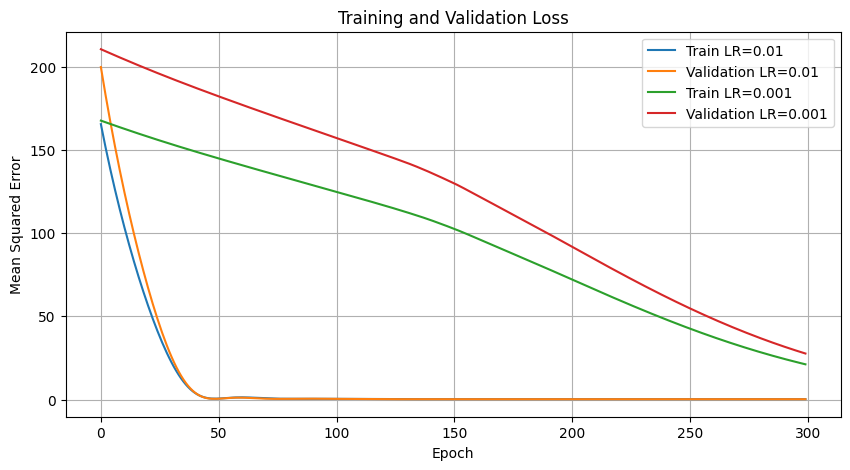

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(train_loss1, label="Train LR=0.01")
plt.plot(val_loss1, label="Validation LR=0.01")

plt.plot(train_loss2, label="Train LR=0.001")
plt.plot(val_loss2, label="Validation LR=0.001")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print("Learning Rate 0.01")
print("Training Loss:", train_loss1[-1])
print("Validation Loss:", val_loss1[-1])

print("\nLearning Rate 0.001")
print("Training Loss:", train_loss2[-1])
print("Validation Loss:", val_loss2[-1])

Learning Rate 0.01
Training Loss: 0.2124524861574173
Validation Loss: 0.18651293218135834

Learning Rate 0.001
Training Loss: 21.179269790649414
Validation Loss: 27.67202377319336


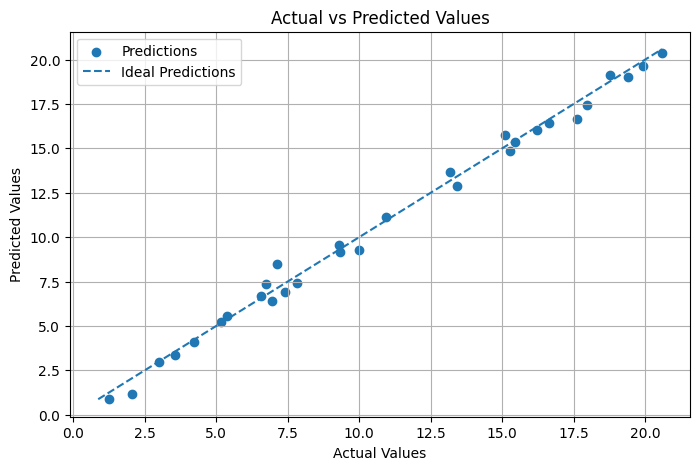

In [ ]:
# Select model
best_model = model1

# Switch to evaluation mode
best_model.eval()

# Predict test outputs
with torch.no_grad():
    predictions = best_model(X_test)

# Convert tensors to NumPy arrays
actual = Y_test.numpy().flatten()
predicted = predictions.numpy().flatten()

# Plot actual and predicted values
plt.figure(figsize=(8, 5))

plt.scatter(actual, predicted, label="Predictions")

# Ideal prediction line
minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Ideal Predictions"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Calculate test MSE
criterion = nn.MSELoss()

with torch.no_grad():
    test_predictions = best_model(X_test)
    test_loss = criterion(test_predictions, Y_test)

print("Test Mean Squared Error:", test_loss.item())

Test Mean Squared Error: 0.24548855423927307


In [ ]:
# New input
new_input = torch.tensor([[10.0]])

# Predict output
best_model.eval()

with torch.no_grad():
    prediction = best_model(new_input)

print("Input:", new_input.item())
print("Predicted Output:", prediction.item())

Input: 10.0
Predicted Output: 20.87764549255371
